# Predicting Sales Prices

 ## Dataset Attributes

 The dataset contains information about houses in Ames, Iowa. The data was collected by the Ames City Assessor’s Office describing 2930 property sales which occurred in Ames, Iowa between 2006 and 2010. The dataset, containing 81 variables, was compiled and published by De Cock in 2011.

 Some of the variables contained in the original dataset have been removed from the the dataset provided to you.
 The dataset provided to you contains the following variables:
* **Year_Built:** year that the house was originally constructed
* **Year_Remod_Add:** year that the house was last remodelled
* **Total_Bsmt_SF:** total size of basement area in square feet
* **First_Flr_SF:** size of the first floor in square feet
* **Second_Flr_SF:** size of the second floor in square feet
* **Gr_Liv_Area:** size of above grade, ground living area in square feet
* **Full_Bath:** number of full above grade bathrooms in the house
* **Half_Bath:** number of half above grade bathrooms in the house
* **Bedroom_AbvGr:** number of above grade bedrooms (does not include basement bedrooms)
* **Kitchen_AbvGr:** number of above grade kitchens
* **TotRms_AbvGrd:** total number of above grade rooms (does not include bathrooms)
* **Fireplaces:** number of fireplaces in the house
* **Garage_Area:** size of garage in square feet
* **Sale_Price:** sale price of the house in dollars


*De Cock, D. (2011). "Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester
Regression Project," Journal of Statistics Education, Volume 19, Number 3.*

- https://ww2.amstat.org/publications/jse/v19n3/decock/DataDocumentation.txt
- http://ww2.amstat.org/publications/jse/v19n3/decock.pdf


 ## Objective

 The goal of this task is to analyse the relationship between these variables and build a multiple linear regression model to predict the sales prices based on the 'Gr_Liv_Area' and 'Garage_Area` variables.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [2]:
df = pd.read_csv("ames.csv")

df.head()

,Year_Built,Year_Remod_Add,Total_Bsmt_SF,First_Flr_SF,Second_Flr_SF,Gr_Liv_Area,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,TotRms_AbvGrd,Fireplaces,Garage_Area,Sale_Price
0,1960,1960,1080,1656,0,1656,1,0,3,1,7,2,528,215000
1,1961,1961,882,896,0,896,1,0,2,1,5,0,730,105000
2,1958,1958,1329,1329,0,1329,1,1,3,1,6,0,312,172000
3,1968,1968,2110,2110,0,2110,2,1,3,1,8,2,522,244000
4,1997,1998,928,928,701,1629,2,1,3,1,6,1,482,189900


In [3]:
# Check for missing values
print(df.isnull().sum())

# Check for duplicate rows
print("Duplicates:", df.duplicated().sum())

# Check data types
print(df.dtypes)

# Remove rows with missing values in selected columns
df = df.dropna(subset=[
    "Gr_Liv_Area",
    "Garage_Area",
    "Sale_Price"
])

# Display descriptive statistics
df.describe()

Year_Built        0
Year_Remod_Add    0
Total_Bsmt_SF     0
First_Flr_SF      0
Second_Flr_SF     0
Gr_Liv_Area       0
Full_Bath         0
Half_Bath         0
Bedroom_AbvGr     0
Kitchen_AbvGr     0
TotRms_AbvGrd     0
Fireplaces        0
Garage_Area       0
Sale_Price        0
dtype: int64
Duplicates: 7
Year_Built        int64
Year_Remod_Add    int64
Total_Bsmt_SF     int64
First_Flr_SF      int64
Second_Flr_SF     int64
Gr_Liv_Area       int64
Full_Bath         int64
Half_Bath         int64
Bedroom_AbvGr     int64
Kitchen_AbvGr     int64
TotRms_AbvGrd     int64
Fireplaces        int64
Garage_Area       int64
Sale_Price        int64
dtype: object


,Year_Built,Year_Remod_Add,Total_Bsmt_SF,First_Flr_SF,Second_Flr_SF,Gr_Liv_Area,Full_Bath,Half_Bath,Bedroom_AbvGr,Kitchen_AbvGr,TotRms_AbvGrd,Fireplaces,Garage_Area,Sale_Price
count,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1971.356314,1984.266553,1051.255631,1159.557679,335.455973,1499.690444,1.566553,0.379522,2.854266,1.044369,6.443003,0.599317,472.658362,180796.060068
std,30.245361,20.860286,440.968018,391.890885,428.395715,505.508887,0.552941,0.502629,0.827731,0.214076,1.572964,0.647921,215.187196,79886.692357
min,1872.000000,1950.000000,0.000000,334.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,12789.000000
25%,1954.000000,1965.000000,793.000000,876.250000,0.000000,1126.000000,1.000000,0.000000,2.000000,1.000000,5.000000,0.000000,320.000000,129500.000000
50%,1973.000000,1993.000000,990.000000,1084.000000,0.000000,1442.000000,2.000000,0.000000,3.000000,1.000000,6.000000,1.000000,480.000000,160000.000000
75%,2001.000000,2004.000000,1301.500000,1384.000000,703.750000,1742.750000,2.000000,1.000000,3.000000,1.000000,7.000000,1.000000,576.000000,213500.000000
max,2010.000000,2010.000000,6110.000000,5095.000000,2065.000000,5642.000000,4.000000,2.000000,8.000000,3.000000,15.000000,4.000000,1488.000000,755000.000000


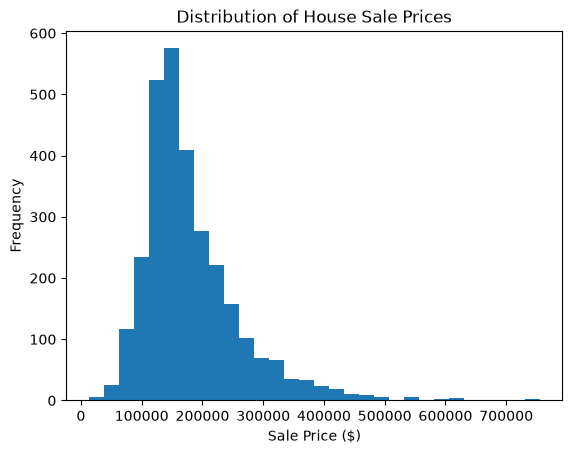

In [4]:
plt.hist(df["Sale_Price"], bins=30)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Frequency")

plt.show()

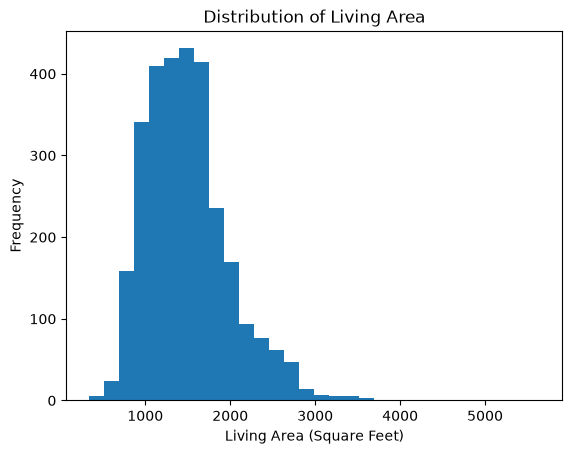

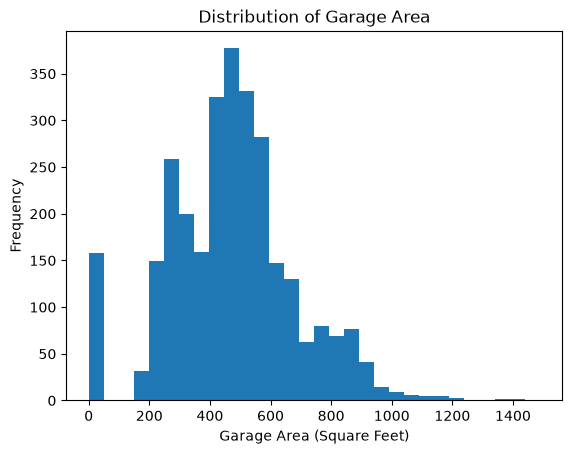

In [5]:
plt.hist(df["Gr_Liv_Area"], bins=30)
plt.title("Distribution of Living Area")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Frequency")
plt.show()

plt.hist(df["Garage_Area"], bins=30)
plt.title("Distribution of Garage Area")
plt.xlabel("Garage Area (Square Feet)")
plt.ylabel("Frequency")
plt.show()

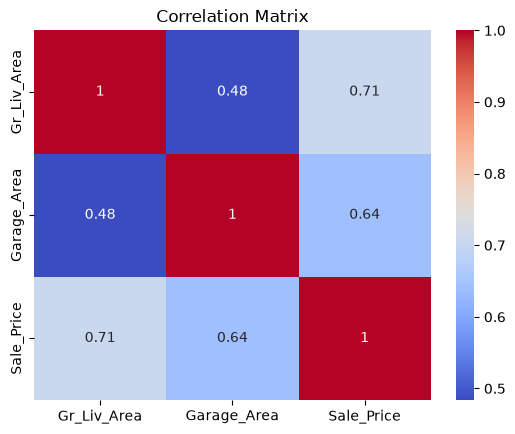

In [6]:
columns = [
    "Gr_Liv_Area",
    "Garage_Area",
    "Sale_Price"
]

correlation = df[columns].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm")

plt.title("Correlation Matrix")
plt.show()

In [7]:
X = df[["Gr_Liv_Area", "Garage_Area"]]

y = df["Sale_Price"]

print(X.head())
print(y.head())

   Gr_Liv_Area  Garage_Area
0         1656          528
1          896          730
2         1329          312
3         2110          522
4         1629          482
0    215000
1    105000
2    172000
3    244000
4    189900
Name: Sale_Price, dtype: int64


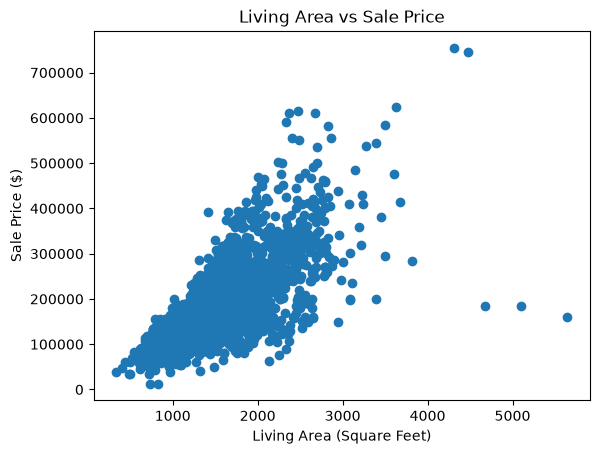

In [8]:
plt.scatter(df["Gr_Liv_Area"], df["Sale_Price"])

plt.title("Living Area vs Sale Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Sale Price ($)")

plt.show()

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Training observations: 2197
Testing observations: 733


In [10]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 78.69,141.15]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['Gr_Liv_Area','Garage_Area']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-5059
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [11]:
print("Intercept:", model.intercept_)

print("Coefficients:", model.coef_)

Intercept: -5059.448195610428
Coefficients: [ 78.69286848 141.14571761]


In [12]:
y_pred = model.predict(X_test)

print(y_pred[:5])

[158224.09430889 113256.67578876 217552.81911301  72846.49160079
  94782.71287234]


In [13]:
results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

print(results.head())

      Actual Price  Predicted Price
1357        161000    158224.094309
2367        116000    113256.675789
2822        196500    217552.819113
2126        123600     72846.491601
1544        126000     94782.712872


In [14]:
mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)

Mean Squared Error: 2634371879.6902103
Root Mean Squared Error: 51326.13252223676


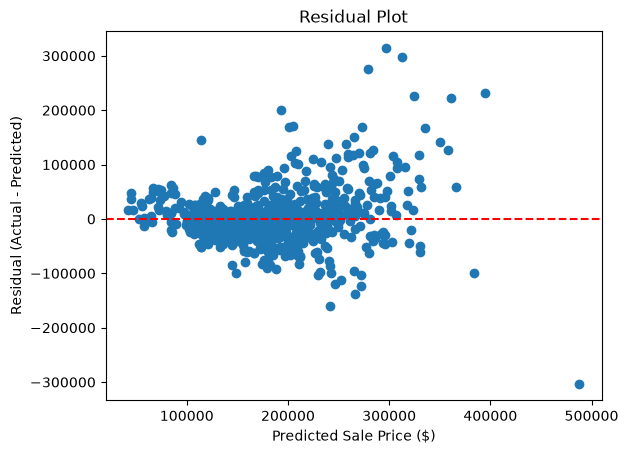

In [15]:
errors = y_test - y_pred

plt.scatter(y_pred, errors)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Sale Price ($)")
plt.ylabel("Residual (Actual - Predicted)")

plt.show()

Interpret coefficients in the context of the prediction:

The residual plot shows that prediction errors are generally distributed around zero, indicating that the model both overestimates and underestimates house sale prices. However, the spread of residuals increases as predicted sale prices rise, suggesting heteroscedasticity. Several outliers are also evident, indicating substantial prediction errors for certain properties. These findings suggest that although living area and garage area contribute to predicting house sale prices, the model's accuracy is limited, particularly for higher-priced properties. Including additional explanatory variables may improve its predictive performance.


In [16]:
median_living_area = df["Gr_Liv_Area"].median()
median_garage_area = df["Garage_Area"].median()

print("Median Living Area:", median_living_area)
print("Median Garage Area:", median_garage_area)

Median Living Area: 1442.0
Median Garage Area: 480.0


In [17]:
median_house = pd.DataFrame({
    "Gr_Liv_Area": [median_living_area],
    "Garage_Area": [median_garage_area]
})

median_prediction = model.predict(median_house)

print("Predicted Price:", median_prediction[0])

print("Actual Median Price:", df["Sale_Price"].median())

Predicted Price: 176165.61260651087
Actual Median Price: 160000.0


**Interpret coefficients in the context of the prediction:**

The multiple linear regression model indicates a positive relationship between living area, garage area and house sale prices. Holding garage area constant, an additional square foot of living area is associated with an estimated increase of $78.69 in the predicted sale price. Similarly, holding living area constant, an additional square foot of garage area is associated with an estimated increase of $141.15.
Using the median living area of 1,442 square feet and median garage area of 480 square feet, the model predicts a sale price of approximately $176,166. This exceeds the dataset's actual median sale price of $160,000. However, this difference does not necessarily indicate systematic overprediction, because the prediction is based on median property characteristics rather than the median of all predicted prices

**Summarise findings**

The analysis examined the relationship between living area, garage area and house sale prices using the Ames Housing dataset, containing 2,930 observations.
Exploratory data analysis indicated that sale prices were positively skewed, with a median of $160,000 and mean of approximately $180,796. Both living area and garage area demonstrated positive relationships with sale price, with correlation coefficients of approximately 0.707 and 0.640, respectively.

A multiple linear regression model was developed using 75% of the observations for training and 25% for testing. Both independent variables had positive estimated coefficients, suggesting that larger living areas and garages are associated with higher predicted selling prices.
The model achieved a root mean squared error of approximately $51,326 on the test set. Although the model captured important relationships, the prediction errors suggest that other variables may be needed to improve accuracy.

Overall, the analysis demonstrates that multiple linear regression can be used to predict house sale prices using property characteristics. Including additional variables, such as property age, location and overall quality, may improve predictive performance.